## Data Preprocessing

Install and import packages

In [5]:
!pip install -q kagglehub

from pathlib import Path
from collections import Counter
import hashlib

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cu130
CUDA available: True


Download the dataset from Kaggle

In [6]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

DATA_DIR = Path(dataset_path)

print("Dataset downloaded to:")
print(DATA_DIR)


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded to:
/kaggle/input/brain-tumor-mri-dataset


Locate the Training and Testing folders




In [7]:
training_matches = [p for p in DATA_DIR.rglob("Training") if p.is_dir()]
testing_matches = [p for p in DATA_DIR.rglob("Testing") if p.is_dir()]

if not training_matches:
    raise FileNotFoundError("Could not find a Training folder in the downloaded dataset.")

if not testing_matches:
    raise FileNotFoundError("Could not find a Testing folder in the downloaded dataset.")

TRAIN_DIR = training_matches[0]
TEST_DIR = testing_matches[0]

print("Training directory:", TRAIN_DIR)
print("Testing directory: ", TEST_DIR)


Training directory: /kaggle/input/brain-tumor-mri-dataset/Training
Testing directory:  /kaggle/input/brain-tumor-mri-dataset/Testing


Inspect the original class counts

In [8]:
for split_dir in [TRAIN_DIR, TEST_DIR]:
    print(f"\n{split_dir.name}")

    total = 0

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            num_images = sum(1 for p in class_dir.iterdir() if p.is_file())
            total += num_images
            print(f"{class_dir.name}: {num_images}")

    print("Total:", total)



Training
glioma: 1400
meningioma: 1400
notumor: 1400
pituitary: 1400
Total: 5600

Testing
glioma: 400
meningioma: 400
notumor: 400
pituitary: 400
Total: 1600


Choose the preprocessing image size

For the baseline CNN, all images will be resized to **128 × 128** and converted to **1-channel grayscale**.


In [9]:
IMG_SIZE = 128
RANDOM_SEED = 42
VALIDATION_SIZE = 0.15
BATCH_SIZE = 32


Create a basic transform

Used to:

- load all images consistently,
- create the training/validation split,
- calculate the training-set mean and standard deviation.
- convert image pixel values from approximately 0–255 to 0–1.


In [10]:
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

base_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=basic_transform
)

print("Classes:", base_dataset.classes)
print("Class mapping:", base_dataset.class_to_idx)
print("Number of provided training images:", len(base_dataset))


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Number of provided training images: 5600


Create the 85% training / 15% validation split




In [11]:
import hashlib
import pandas as pd
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

DUPLICATE_THRESHOLD = 10
CHUNK_SIZE = 256

test_base_dataset = datasets.ImageFolder(root=TEST_DIR)

all_samples = base_dataset.samples + test_base_dataset.samples
all_labels = np.array([label for _, label in all_samples])
is_train_image = np.arange(len(all_samples)) < len(base_dataset)


def get_image_hash(file_path, hash_size=16):
    image = Image.open(file_path).convert("L")
    image = image.resize((hash_size + 1, hash_size), Image.BILINEAR)
    pixels = np.asarray(image, dtype=np.int16)

    return np.packbits(pixels[:, 1:] > pixels[:, :-1])


def get_file_hash(file_path):
    with open(file_path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


image_hashes = np.stack([get_image_hash(path) for path, _ in all_samples])
file_hashes = pd.Series([get_file_hash(path) for path, _ in all_samples])
bit_counts = np.array([bin(i).count("1") for i in range(256)])

parent = list(range(len(all_samples)))


def find_group(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]

    return i


def merge_groups(i, j):
    parent[find_group(j)] = find_group(i)


for matching_indices in file_hashes.groupby(file_hashes).indices.values():
    for j in matching_indices[1:]:
        merge_groups(matching_indices[0], j)

for start in range(0, len(image_hashes), CHUNK_SIZE):
    chunk = image_hashes[start:start + CHUNK_SIZE]
    distances = bit_counts[chunk[:, None] ^ image_hashes[None]].sum(-1)

    for i, j in zip(*np.nonzero(distances <= DUPLICATE_THRESHOLD)):
        if start + i < j:
            merge_groups(start + i, j)

group_ids = np.array([find_group(i) for i in range(len(all_samples))])

group_table = pd.DataFrame({
    "group": group_ids,
    "label": all_labels,
    "is_train": is_train_image
})

bad_groups = [
    group
    for group, rows in group_table.groupby("group")
    if rows.is_train.nunique() > 1 or rows.label.nunique() > 1
]

kept_indices = np.flatnonzero(is_train_image & ~np.isin(group_ids, bad_groups))

print("Dropped training images:", is_train_image.sum() - len(kept_indices))

splitter = StratifiedGroupKFold(
    n_splits=round(1 / VALIDATION_SIZE),
    shuffle=True,
    random_state=RANDOM_SEED
)

train_positions, val_positions = next(
    splitter.split(
        kept_indices,
        all_labels[kept_indices],
        groups=group_ids[kept_indices]
    )
)

train_indices = kept_indices[train_positions]
val_indices = kept_indices[val_positions]

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))

Dropped training images: 752
Training images: 4159
Validation images: 689


Calculate normalization statistics using training data only




In [12]:
stats_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=basic_transform
)

stats_subset = Subset(stats_dataset, train_indices)

stats_loader = DataLoader(
    stats_subset,
    batch_size=64,
    shuffle=False
)

pixel_sum = torch.zeros(1)
pixel_squared_sum = torch.zeros(1)
num_pixels = 0

for images, _ in stats_loader:
    pixel_sum += images.sum(dim=[0, 2, 3])
    pixel_squared_sum += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += (
        images.shape[0]
        * images.shape[2]
        * images.shape[3]
    )

mean = pixel_sum / num_pixels
std = torch.sqrt(pixel_squared_sum / num_pixels - mean ** 2)

MEAN = mean.item()
STD = std.item()

print("Training mean:", MEAN)
print("Training standard deviation:", STD)


Training mean: 0.17541201412677765
Training standard deviation: 0.1828196942806244


Define the final preprocessing transforms

Training set
The training images receive mild augmentation:

- small random rotation,
- horizontal flip,
- small translation,
- small scaling.

Validation and test sets
No random augmentation is applied. They receive only:

- resize,
- grayscale conversion,
- tensor conversion,
- normalization.


In [13]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=1),

    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[MEAN],
        std=[STD]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[MEAN],
        std=[STD]
    )
])


Build the training, validation, and test datasets




In [14]:
train_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=eval_transform
)

train_dataset = Subset(
    train_full,
    train_indices
)

val_dataset = Subset(
    val_full,
    val_indices
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Training samples: 4159
Validation samples: 689
Test samples: 1600


Verify that training and testing use the same label mapping




In [15]:
print("Training mapping:", train_full.class_to_idx)
print("Testing mapping: ", test_dataset.class_to_idx)

assert train_full.class_to_idx == test_dataset.class_to_idx

print("Label mappings match.")


Training mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Testing mapping:  {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Label mappings match.


Create DataLoaders

In [16]:
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

print("DataLoaders created.")


DataLoaders created.


Check one batch




In [17]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])


Image batch shape: torch.Size([32, 1, 128, 128])
Label batch shape: torch.Size([32])
First 10 labels: tensor([1, 1, 1, 2, 1, 3, 1, 2, 1, 1])


Check class distribution after the split

In [18]:
train_labels = [base_dataset.targets[i] for i in train_indices]
val_labels = [base_dataset.targets[i] for i in val_indices]

print("Class counts after splitting:\n")

for class_index, class_name in enumerate(base_dataset.classes):
    train_count = train_labels.count(class_index)
    val_count = val_labels.count(class_index)

    print(
        f"{class_name:15s} "
        f"Train: {train_count:4d}  "
        f"Validation: {val_count:4d}"
    )


Class counts after splitting:

glioma          Train: 1194  Validation:  201
meningioma      Train: 1109  Validation:  185
notumor         Train:  652  Validation:  108
pituitary       Train: 1204  Validation:  195


Visually inspect processed training images




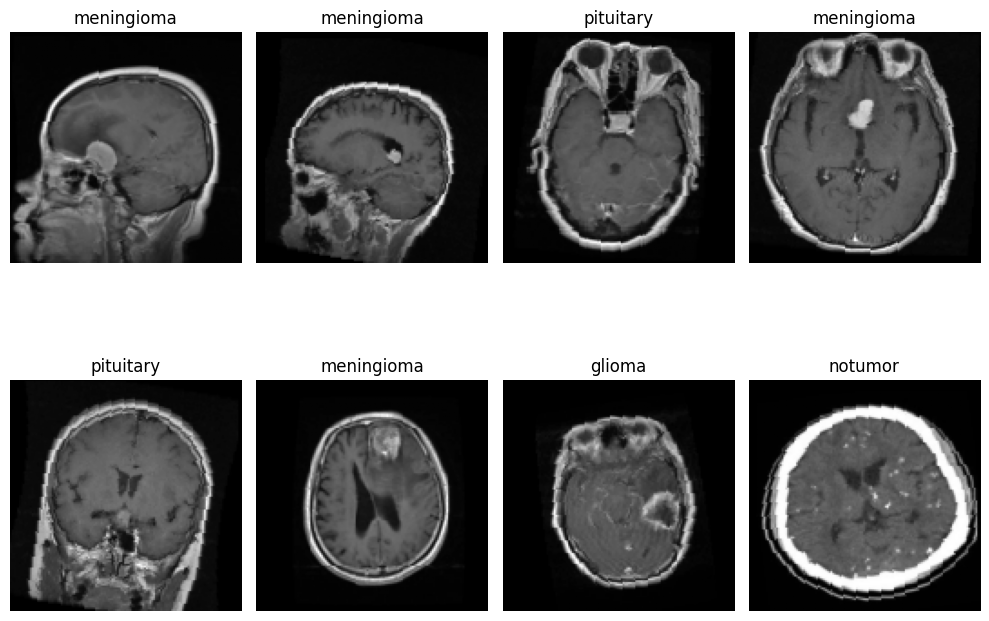

In [19]:
class_names = train_full.classes

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 8))

for i in range(min(8, len(images))):
    image = images[i].clone()

    # Undo normalization for visualization
    image = image * STD + MEAN

    plt.subplot(2, 4, i + 1)
    plt.imshow(image.squeeze().numpy(), cmap="gray")
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()


Basic train/test leakage check

This checks whether an exact duplicate file occurs in both the provided Training and Testing folders.



In [20]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_hash(file_path):
    with open(file_path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


train_hashes = {}

for file in TRAIN_DIR.rglob("*"):
    if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
        train_hashes[get_hash(file)] = file


duplicates = []

for file in TEST_DIR.rglob("*"):
    if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
        image_hash = get_hash(file)

        if image_hash in train_hashes:
            duplicates.append(
                (train_hashes[image_hash], file)
            )


print("Exact train/test duplicates:", len(duplicates))

if duplicates:
    print("\nFirst few duplicates:")
    for train_file, test_file in duplicates[:10]:
        print("TRAIN:", train_file)
        print("TEST: ", test_file)
        print()


Exact train/test duplicates: 0


In [24]:
import copy
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

Selected device: cuda


In [25]:
class ConvBNReLU(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
        use_bn=True,
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            bias=not use_bn,
        )
        self.bn = nn.BatchNorm2d(out_channels) if use_bn else nn.Identity()
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x

In [26]:
class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4, dropout=0.30, use_bn=True):
        super().__init__()
        self.block1 = nn.Sequential(
            ConvBNReLU(1, 32, use_bn=use_bn),
            nn.MaxPool2d(2),
        )
        self.block2 = nn.Sequential(
            ConvBNReLU(32, 64, use_bn=use_bn),
            ConvBNReLU(64, 64, use_bn=use_bn),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            ConvBNReLU(64, 128, use_bn=use_bn),
            nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [27]:
def initialize_weights(module):
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(
            module.weight, mode="fan_in", nonlinearity="relu"
        )
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.01)
        if module.bias is not None:
            nn.init.zeros_(module.bias)

_model = BrainTumorCNN(num_classes=4, dropout=0.30)
_model.apply(initialize_weights)
_logits = _model(torch.randn(8, 1, IMG_SIZE, IMG_SIZE))
print("Output shape:", _logits.shape)
print("Trainable parameters:", sum(p.numel() for p in _model.parameters()))
assert _logits.shape == (8, 4)

Output shape: torch.Size([8, 4])
Trainable parameters: 130404


In [28]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples

In [29]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples

In [30]:
def fit_model(
    model, train_loader, val_loader,
    lr=1e-3, weight_decay=1e-4, epochs=4,
    device=DEVICE, verbose=True
):
    model = model.to(device)
    class_counts = torch.bincount(torch.tensor(train_labels), minlength=4).float()
    class_weights = class_counts.sum() / (len(class_counts) * class_counts)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=max(1, epochs // 2), gamma=0.3
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [], "lr": []
    }
    best_val_acc = -float("inf")
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["train_acc"].append(float(train_acc))
        history["val_acc"].append(float(val_acc))
        history["lr"].append(float(current_lr))

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"train acc {100*train_acc:.2f}% | "
                f"val acc {100*val_acc:.2f}% | "
                f"lr {current_lr:.5f}"
            )

        scheduler.step()

    model.load_state_dict(best_state)
    return history

In [31]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score
@torch.no_grad()
def detailed_eval(model, loader, class_names, device=DEVICE):
  model.eval()
  preds, targets =[],[]
  for images, labels in loader:
    preds.append(model(images.to(device)).argmax(1).cpu())
    targets.append(labels)
  preds = torch.cat(preds).numpy()
  targets = torch.cat(targets).numpy()
  return{
      "accuracy": float((preds == targets).mean()),
        "macro_f1": float(f1_score(targets, preds, average="macro")),
        "report": classification_report(targets, preds, target_names=class_names,
                                        output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(
            targets, preds, labels=list(range(len(class_names)))).tolist(),
        "preds": preds,
        "targets": targets,
  }

In [32]:
def plot_curves(history, title=None, save_path=None):
    epochs = range(1, len(history["train_loss"])+1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].plot(epochs, history["train_loss"], label="train")
    axs[0].plot(epochs, history["val_loss"], label="val")
    axs[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
    axs[1].plot(epochs, history["train_acc"], label="train")
    axs[1].plot(epochs, history["val_acc"], label="val")
    axs[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    for ax in axs:
        ax.legend()
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()

Epoch 01/40 | train acc 63.24% | val acc 63.13% | lr 0.00100
Epoch 02/40 | train acc 74.32% | val acc 68.07% | lr 0.00100
Epoch 03/40 | train acc 78.17% | val acc 69.96% | lr 0.00100
Epoch 04/40 | train acc 79.73% | val acc 76.49% | lr 0.00100
Epoch 05/40 | train acc 81.85% | val acc 75.18% | lr 0.00100
Epoch 06/40 | train acc 81.29% | val acc 80.84% | lr 0.00100
Epoch 07/40 | train acc 82.35% | val acc 74.31% | lr 0.00100
Epoch 08/40 | train acc 82.40% | val acc 78.52% | lr 0.00100
Epoch 09/40 | train acc 83.72% | val acc 82.00% | lr 0.00100
Epoch 10/40 | train acc 84.01% | val acc 83.31% | lr 0.00100
Epoch 11/40 | train acc 83.96% | val acc 80.41% | lr 0.00100
Epoch 12/40 | train acc 83.46% | val acc 83.45% | lr 0.00100
Epoch 13/40 | train acc 84.85% | val acc 79.39% | lr 0.00100
Epoch 14/40 | train acc 85.74% | val acc 80.84% | lr 0.00100
Epoch 15/40 | train acc 85.60% | val acc 76.49% | lr 0.00100
Epoch 16/40 | train acc 85.12% | val acc 81.86% | lr 0.00100
Epoch 17/40 | train acc 

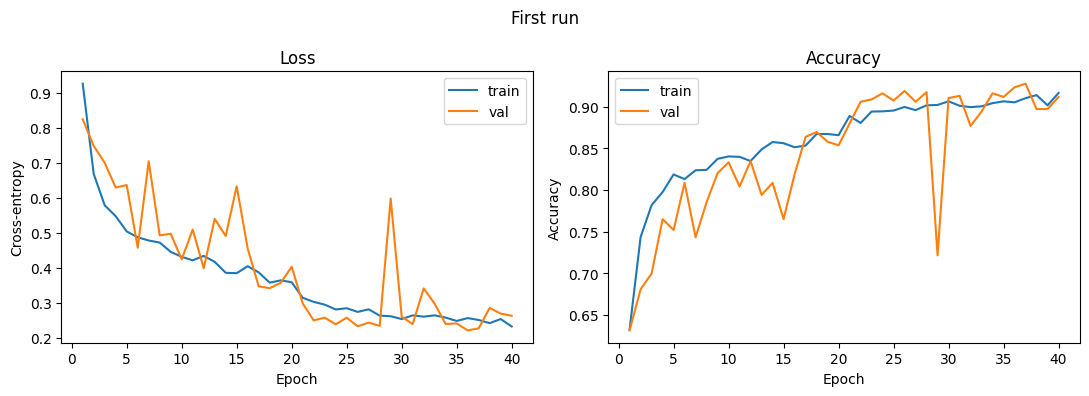

{'lr': 0.001, 'weight_decay': 0.0001, 'epochs': 40, 'dropout': 0.3}
Val acc 92.74% | macro F1 0.931
              precision    recall  f1-score   support

      glioma      0.931     0.935     0.933       201
  meningioma      0.880     0.876     0.878       185
     notumor      0.939     0.991     0.964       108
   pituitary      0.963     0.933     0.948       195

    accuracy                          0.927       689
   macro avg      0.928     0.934     0.931       689
weighted avg      0.928     0.927     0.927       689

[[188  12   1   0]
 [ 13 162   3   7]
 [  0   1 107   0]
 [  1   9   3 182]]


In [ ]:
FIRST_RUN_CONFIG = {"lr": 1e-3, "weight_decay": 1e-4, "epochs": 40, "dropout": 0.30}

model = BrainTumorCNN(num_classes=4, dropout=FIRST_RUN_CONFIG["dropout"])
model.apply(initialize_weights)

history = fit_model(
    model, train_loader, val_loader,
    lr=FIRST_RUN_CONFIG["lr"],
    weight_decay=FIRST_RUN_CONFIG["weight_decay"],
    epochs=FIRST_RUN_CONFIG["epochs"],
    device=DEVICE,
    verbose=True,
)
metrics = detailed_eval(model, val_loader, class_names)
plot_curves(history, title="First run")
print(FIRST_RUN_CONFIG)
print(f"Val acc {100*metrics['accuracy']:.2f}% | macro F1 {metrics['macro_f1']:.3f}")
print(classification_report(metrics["targets"], metrics["preds"], target_names=class_names, digits=3))
print(confusion_matrix(metrics["targets"], metrics["preds"]))

In [ ]:
torch.save(model.state_dict(), "best_model.pt")

val_results = detailed_eval(model, val_loader, class_names)
print(f"Val: accuracy {val_results['accuracy']:.3f}, macro-F1 {val_results['macro_f1']:.3f}")

print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Train / Val / Test sizes:", len(train_dataset), len(val_dataset), len(test_dataset))

Val: accuracy 0.927, macro-F1 0.931
Parameters: 130404
Train / Val / Test sizes: 4159 689 1600


corruption  level  macro_f1  glioma_recall  meningioma_recall  notumor_recall  pituitary_recall
      none   0.00     0.931          0.935              0.876           0.991             0.933
     noise   0.02     0.304          0.005              0.000           0.880             0.995
     noise   0.05     0.205          0.000              0.000           0.963             0.390
     noise   0.10     0.068          0.000              0.000           1.000             0.000
     noise   0.20     0.068          0.000              0.000           1.000             0.000
      blur   0.50     0.824          0.930              0.876           0.981             0.564
      blur   1.00     0.480          0.896              0.616           0.778             0.000
      blur   2.00     0.371          0.891              0.389           0.491             0.000
      blur   3.00     0.346          0.881              0.335           0.463             0.000
brightness   0.50     0.363          0.9

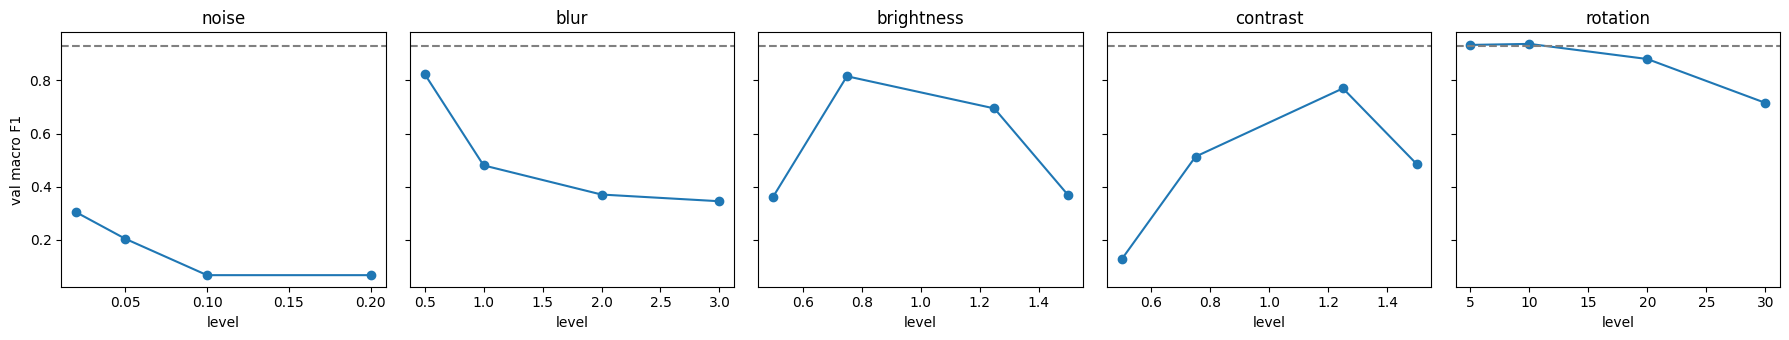

In [ ]:
import torchvision.transforms.functional as TF
import pandas as pd
from sklearn.metrics import f1_score, recall_score

CORRUPTIONS = {
    "noise": (lambda x, s: (x + s * torch.randn_like(x)).clamp(0, 1), [0.02, 0.05, 0.1, 0.2]),
    "blur": (lambda x, s: TF.gaussian_blur(x, 2 * int(3 * s) + 1, s), [0.5, 1, 2, 3]),
    "brightness": (TF.adjust_brightness, [0.5, 0.75, 1.25, 1.5]),
    "contrast": (TF.adjust_contrast, [0.5, 0.75, 1.25, 1.5]),
    "rotation": (TF.rotate, [5, 10, 20, 30]),
}


@torch.no_grad()
def eval_corrupted(corrupt, level):
    model.eval()
    torch.manual_seed(RANDOM_SEED)
    preds, targets = [], []

    for images, labels in val_loader:
        images = corrupt(images.to(DEVICE) * STD + MEAN, level)
        preds.append(model((images - MEAN) / STD).argmax(1).cpu())
        targets.append(labels)

    preds, targets = torch.cat(preds), torch.cat(targets)
    return [f1_score(targets, preds, average="macro"), *recall_score(targets, preds, average=None)]


rows = [["none", 0, *eval_corrupted(lambda x, s: x, 0)]]
for name, (corrupt, levels) in CORRUPTIONS.items():
    rows += [[name, level, *eval_corrupted(corrupt, level)] for level in levels]

robustness = pd.DataFrame(rows, columns=["corruption", "level", "macro_f1"] + [f"{c}_recall" for c in class_names])
print(robustness.round(3).to_string(index=False))

fig, axs = plt.subplots(1, len(CORRUPTIONS), figsize=(18, 3.5), sharey=True)
for ax, name in zip(axs, CORRUPTIONS):
    r = robustness[robustness.corruption == name]
    ax.plot(r.level, r.macro_f1, marker="o")
    ax.axhline(robustness.macro_f1[0], color="gray", linestyle="--")
    ax.set(title=name, xlabel="level")
axs[0].set_ylabel("val macro F1")
fig.tight_layout()
plt.savefig("robustness_f1.png")
plt.show()

Train: accuracy 0.940, macro-F1 0.941
Test:  accuracy 0.818, macro-F1 0.814


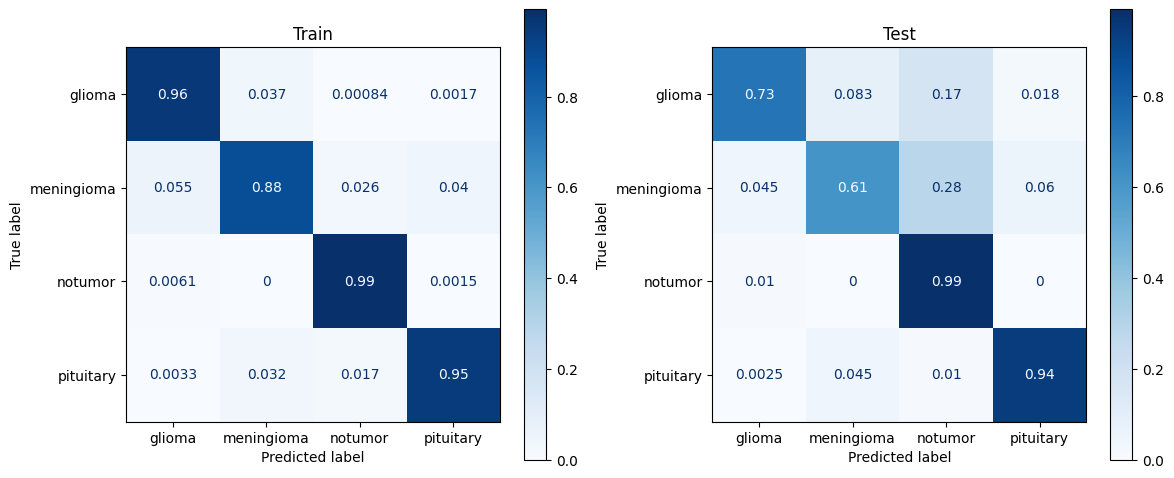

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

train_eval_loader = DataLoader(Subset(val_full, train_indices), batch_size=BATCH_SIZE, shuffle=False)

train_results = detailed_eval(model, train_eval_loader, class_names)
test_results = detailed_eval(model, test_loader, class_names)

print(f"Train: accuracy {train_results['accuracy']:.3f}, macro-F1 {train_results['macro_f1']:.3f}")
print(f"Test:  accuracy {test_results['accuracy']:.3f}, macro-F1 {test_results['macro_f1']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    train_results["targets"], train_results["preds"],
    display_labels=class_names, normalize="true", ax=axes[0], cmap="Blues")
axes[0].set_title("Train")

ConfusionMatrixDisplay.from_predictions(
    test_results["targets"], test_results["preds"],
    display_labels=class_names, normalize="true", ax=axes[1], cmap="Blues")
axes[1].set_title("Test")

plt.tight_layout()
plt.savefig("confusion_train_vs_test.png", dpi=200)
plt.show()

In [ ]:
detailed_eval(model, val_loader, class_names)

{'accuracy': 0.9274310595065312,
 'macro_f1': 0.9307329731270034,
 'report': {'glioma': {'precision': 0.9306930693069307,
   'recall': 0.9353233830845771,
   'f1-score': 0.9330024813895782,
   'support': 201.0},
  'meningioma': {'precision': 0.8804347826086957,
   'recall': 0.8756756756756757,
   'f1-score': 0.8780487804878049,
   'support': 185.0},
  'notumor': {'precision': 0.9385964912280702,
   'recall': 0.9907407407407407,
   'f1-score': 0.963963963963964,
   'support': 108.0},
  'pituitary': {'precision': 0.9629629629629629,
   'recall': 0.9333333333333333,
   'f1-score': 0.9479166666666666,
   'support': 195.0},
  'accuracy': 0.9274310595065312,
  'macro avg': {'precision': 0.9281718265266649,
   'recall': 0.9337682832085819,
   'f1-score': 0.9307329731270034,
   'support': 689.0},
  'weighted avg': {'precision': 0.9275703055786808,
   'recall': 0.9274310595065312,
   'f1-score': 0.927321308066266,
   'support': 689.0}},
 'confusion_matrix': [[188, 12, 1, 0],
  [13, 162, 3, 7],


Most common test mistakes:
  meningioma -> notumor: 114
  glioma -> notumor: 69
  glioma -> meningioma: 33
  meningioma -> pituitary: 24
  pituitary -> meningioma: 18

Missed tumors (tumor -> notumor): 187 of 1200


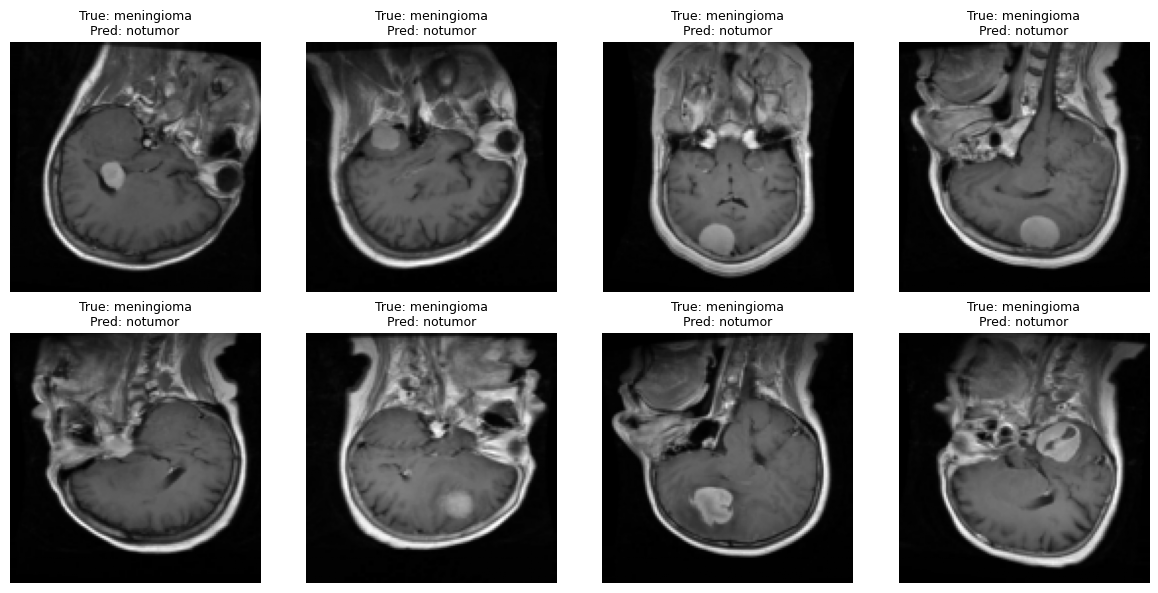

In [ ]:
cm = np.array(test_results["confusion_matrix"])
mistakes = []
for true_i in range(len(class_names)):
    for pred_i in range(len(class_names)):
        if true_i != pred_i:
            mistakes.append((cm[true_i, pred_i], class_names[true_i], class_names[pred_i]))
mistakes.sort(reverse=True)

print("Most common test mistakes:")
for count, true_name, pred_name in mistakes[:5]:
    print(f"  {true_name} -> {pred_name}: {count}")

notumor_i = class_names.index("notumor")
missed = sum(cm[i, notumor_i] for i in range(len(class_names)) if i != notumor_i)
tumor_total = sum(cm[i].sum() for i in range(len(class_names)) if i != notumor_i)
print(f"\nMissed tumors (tumor -> notumor): {missed} of {tumor_total}")

_, true_name, pred_name = mistakes[0]
true_i, pred_i = class_names.index(true_name), class_names.index(pred_name)

wrong_idx = [i for i in range(len(test_dataset))
             if test_results["targets"][i] == true_i and test_results["preds"][i] == pred_i][:8]

plt.figure(figsize=(12, 6))
for k, i in enumerate(wrong_idx):
    img, _ = test_dataset[i]
    plt.subplot(2, 4, k + 1)
    plt.imshow((img.squeeze() * STD + MEAN).numpy(), cmap="gray")
    plt.title(f"True: {true_name}\nPred: {pred_name}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.savefig("top_mistakes.png", dpi=200)
plt.show()

In [ ]:
import time
import pandas as pd

HP_EPOCHS = 15
BASE_HP = {"lr": 1e-3, "batch_size": 32}

SWEEPS = {
    "lr": [1e-4, 3e-4, 1e-3, 3e-3],
    "batch_size": [16, 32, 64],
}

def run_hp(cfg):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    hp_train_loader = DataLoader(train_dataset, batch_size=cfg["batch_size"],
                                 shuffle=True, num_workers=2, pin_memory=PIN_MEMORY)
    m = BrainTumorCNN(num_classes=4, dropout=0.30)
    m.apply(initialize_weights)

    start = time.time()
    hist = fit_model(m, hp_train_loader, val_loader, lr=cfg["lr"],
                     weight_decay=1e-4, epochs=HP_EPOCHS, verbose=False)
    res = detailed_eval(m, val_loader, class_names)
    best = int(np.argmax(hist["val_acc"]))

    return hist, {
        "best_epoch": best + 1,
        "val_acc": res["accuracy"],
        "val_macro_f1": res["macro_f1"],
        "gap": hist["train_acc"][best] - hist["val_acc"][best],
        "minutes": (time.time() - start) / 60,
    }

hp_rows, hp_histories = [], {}
for param, values in SWEEPS.items():
    for v in values:
        name = f"{param}={v}"
        print("Running", name)
        hist, summary = run_hp({**BASE_HP, param: v})
        hp_histories[name] = hist
        hp_rows.append({"param": param, "value": v, **summary})
        print(f"  val acc {100*summary['val_acc']:.2f}% | macro F1 {summary['val_macro_f1']:.3f} "
              f"| gap {summary['gap']:.3f} | {summary['minutes']:.1f} min")

hp_results = pd.DataFrame(hp_rows)
print(hp_results.round(3).to_string(index=False))

Running lr=0.0001
  val acc 75.47% | macro F1 0.771 | gap -0.003 | 47.1 min
Running lr=0.0003
  val acc 83.60% | macro F1 0.846 | gap -0.012 | 47.0 min
Running lr=0.001


In [ ]:
print(hp_results.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

     param  value  best_epoch  val_acc  val_macro_f1      gap  minutes
        lr 0.0001          14    0.762        0.7781 0.003835    4.034
        lr 0.0003          11   0.8389         0.848 -0.02067    4.024
        lr  0.001          14   0.8766        0.8834 -0.02378    4.506
        lr  0.003          15   0.8708        0.8797 0.007509     4.18
batch_size     16          14   0.8752        0.8825 -0.02353    4.207
batch_size     32          14   0.8723         0.881 -0.01775    4.297
batch_size     64          12   0.8665        0.8768  -0.0242    4.112


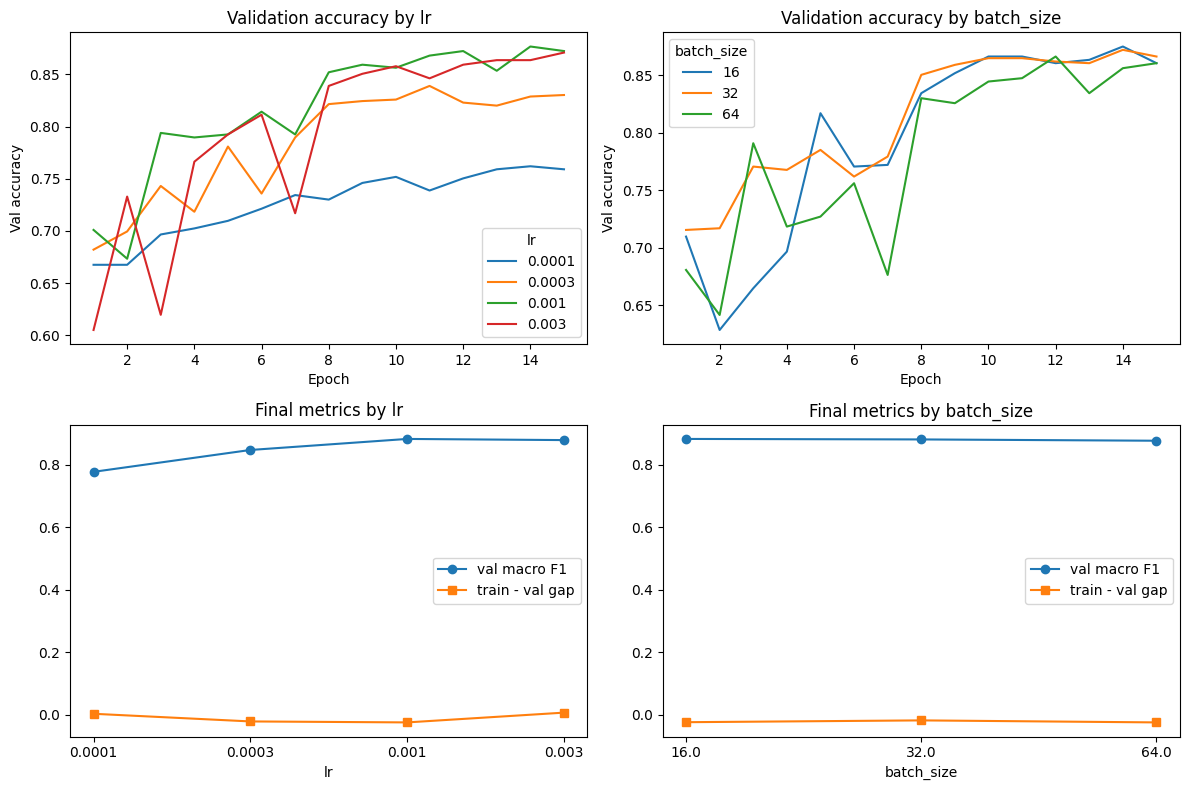

In [ ]:
fig, axs = plt.subplots(2, len(SWEEPS), figsize=(12, 8))

for col, (param, values) in enumerate(SWEEPS.items()):
    for v in values:
        axs[0, col].plot(range(1, HP_EPOCHS + 1), hp_histories[f"{param}={v}"]["val_acc"], label=str(v))
    axs[0, col].set(title=f"Validation accuracy by {param}", xlabel="Epoch", ylabel="Val accuracy")
    axs[0, col].legend(title=param)

    r = hp_results[hp_results.param == param]
    labels = [str(v) for v in r.value.tolist()]
    axs[1, col].plot(labels, r.val_macro_f1, marker="o", label="val macro F1")
    axs[1, col].plot(labels, r.gap, marker="s", label="train - val gap")
    axs[1, col].set(title=f"Final metrics by {param}", xlabel=param)
    axs[1, col].legend()

fig.tight_layout()
plt.savefig("hp_study.png", dpi=200)
plt.show()

## Regularization Experiment


In [33]:
def reset_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [34]:
REGULARIZATION_CONFIGS = {
    "Baseline": {
        "dropout": 0.0,
        "use_bn": False,
        "weight_decay": 0.0
    },

    "Dropout": {
        "dropout": 0.30,
        "use_bn": False,
        "weight_decay": 0.0
    },

    "BatchNorm": {
        "dropout": 0.0,
        "use_bn": True,
        "weight_decay": 0.0
    },

    "Dropout + BatchNorm": {
        "dropout": 0.30,
        "use_bn": True,
        "weight_decay": 0.0
    }
}

REGULARIZATION_CONFIGS

{'Baseline': {'dropout': 0.0, 'use_bn': False, 'weight_decay': 0.0},
 'Dropout': {'dropout': 0.3, 'use_bn': False, 'weight_decay': 0.0},
 'BatchNorm': {'dropout': 0.0, 'use_bn': True, 'weight_decay': 0.0},
 'Dropout + BatchNorm': {'dropout': 0.3, 'use_bn': True, 'weight_decay': 0.0}}

In [36]:
regularization_histories = {}
regularization_models = {}
regularization_results = []

REG_EPOCHS = 40
REG_LR = 1e-3

for name, config in REGULARIZATION_CONFIGS.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # Reset before model creation so initialization is reproducible.
    reset_seed(SEED)

    model_reg = BrainTumorCNN(
        num_classes=4,
        dropout=config["dropout"],
        use_bn=config["use_bn"]
    )

    model_reg.apply(initialize_weights)

    # Reset again before training so the random training sequence
    # begins consistently across experiments.
    reset_seed(SEED)

    history_reg = fit_model(
        model_reg,
        train_loader,
        val_loader,
        lr=REG_LR,
        weight_decay=config["weight_decay"],
        epochs=REG_EPOCHS,
        device=DEVICE,
        verbose=True
    )

    metrics_reg = detailed_eval(
        model_reg,
        val_loader,
        class_names,
        device=DEVICE
    )

    best_index = int(np.argmax(history_reg["val_acc"]))
    best_epoch = best_index + 1

    train_acc_best = history_reg["train_acc"][best_index]
    val_acc_best = history_reg["val_acc"][best_index]
    generalization_gap = train_acc_best - val_acc_best

    regularization_histories[name] = history_reg
    regularization_models[name] = copy.deepcopy(model_reg).cpu()

    regularization_results.append({
        "Model": name,
        "Dropout": config["dropout"],
        "BatchNorm": config["use_bn"],
        "Weight Decay": config["weight_decay"],
        "Best Epoch": best_epoch,
        "Train Accuracy": train_acc_best,
        "Validation Accuracy": metrics_reg["accuracy"],
        "Validation Macro F1": metrics_reg["macro_f1"],
        "Generalization Gap": generalization_gap
    })

    print(f"\n{name}")
    print(f"Validation Accuracy: {100 * metrics_reg['accuracy']:.2f}%")
    print(f"Validation Macro F1: {metrics_reg['macro_f1']:.3f}")
    print(f"Best Epoch: {best_epoch}")


Baseline
Epoch 01/40 | train acc 54.87% | val acc 65.60% | lr 0.00100
Epoch 02/40 | train acc 68.38% | val acc 71.70% | lr 0.00100
Epoch 03/40 | train acc 71.05% | val acc 71.70% | lr 0.00100
Epoch 04/40 | train acc 71.10% | val acc 66.47% | lr 0.00100
Epoch 05/40 | train acc 75.09% | val acc 74.60% | lr 0.00100
Epoch 06/40 | train acc 76.32% | val acc 77.65% | lr 0.00100
Epoch 07/40 | train acc 77.81% | val acc 76.92% | lr 0.00100
Epoch 08/40 | train acc 79.47% | val acc 80.12% | lr 0.00100
Epoch 09/40 | train acc 79.87% | val acc 80.70% | lr 0.00100
Epoch 10/40 | train acc 80.00% | val acc 77.07% | lr 0.00100
Epoch 11/40 | train acc 82.42% | val acc 84.03% | lr 0.00100
Epoch 12/40 | train acc 83.00% | val acc 82.29% | lr 0.00100
Epoch 13/40 | train acc 83.94% | val acc 84.33% | lr 0.00100
Epoch 14/40 | train acc 85.00% | val acc 84.18% | lr 0.00100
Epoch 15/40 | train acc 84.11% | val acc 86.07% | lr 0.00100
Epoch 16/40 | train acc 85.74% | val acc 85.78% | lr 0.00100
Epoch 17/40 | 

In [37]:
regularization_df = pd.DataFrame(regularization_results)

regularization_df = regularization_df.sort_values(
    by="Validation Macro F1",
    ascending=False
).reset_index(drop=True)

regularization_df

,Model,Dropout,BatchNorm,Weight Decay,Best Epoch,Train Accuracy,Validation Accuracy,Validation Macro F1,Generalization Gap
0,BatchNorm,0.0,True,0.0,33,0.923780,0.937591,0.941959,-0.013811
1,Dropout + BatchNorm,0.3,True,0.0,40,0.899976,0.928882,0.933089,-0.028906
2,Baseline,0.0,False,0.0,40,0.924982,0.917271,0.920057,0.007711
3,Dropout,0.3,False,0.0,40,0.906468,0.910015,0.911600,-0.003547


In [ ]:
plt.figure(figsize=(10, 6))

for name, history_reg in regularization_histories.items():
    epochs = range(1, len(history_reg["val_acc"]) + 1)

    plt.plot(
        epochs,
        history_reg["val_acc"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Regularization Method")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

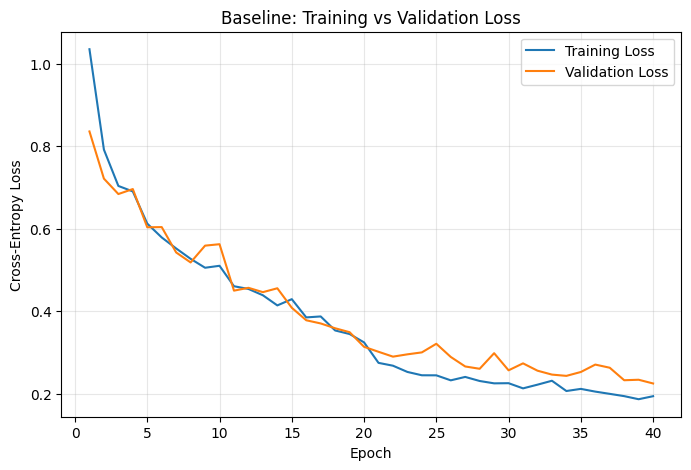

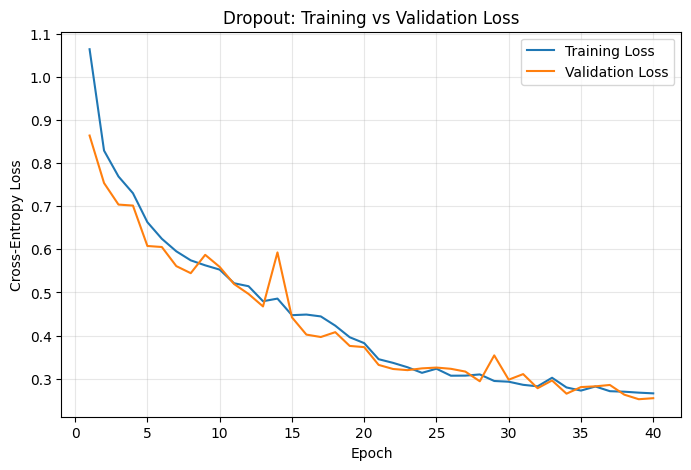

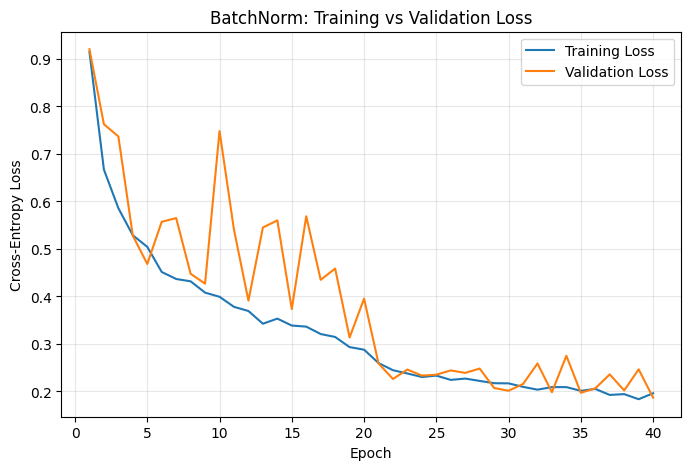

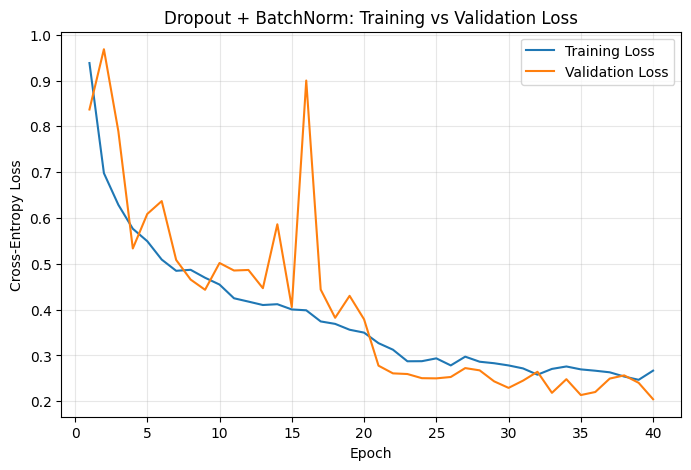

In [38]:
for name, history_reg in regularization_histories.items():

    epochs = range(1, len(history_reg["train_loss"]) + 1)

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history_reg["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history_reg["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.title(f"{name}: Training vs Validation Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

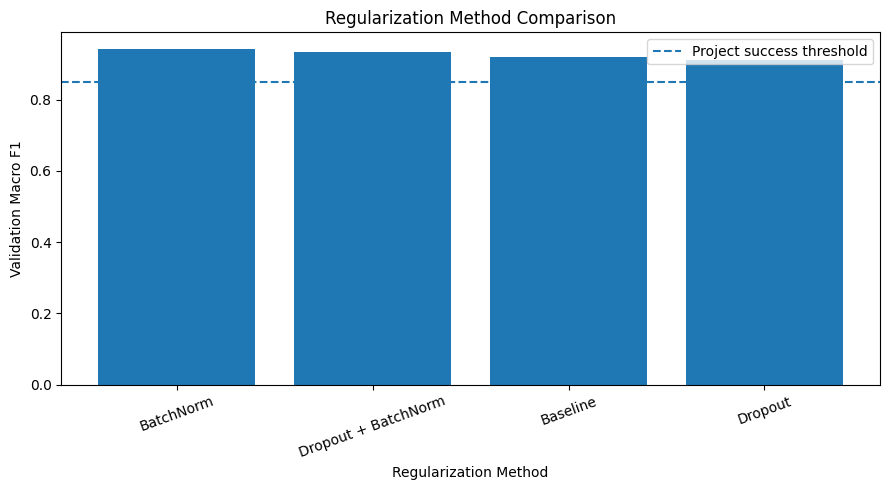

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    regularization_df["Model"],
    regularization_df["Validation Macro F1"]
)

plt.axhline(
    y=0.85,
    linestyle="--",
    label="Project success threshold"
)

plt.ylabel("Validation Macro F1")
plt.xlabel("Regularization Method")
plt.title("Regularization Method Comparison")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

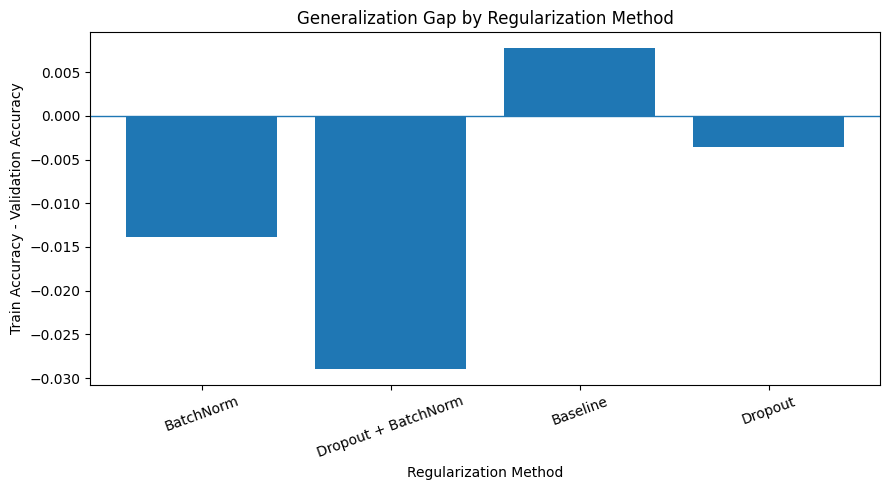

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(
    regularization_df["Model"],
    regularization_df["Generalization Gap"]
)

plt.axhline(y=0, linewidth=1)

plt.ylabel("Train Accuracy - Validation Accuracy")
plt.xlabel("Regularization Method")
plt.title("Generalization Gap by Regularization Method")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [41]:
best_row = regularization_df.iloc[0]
best_name = best_row["Model"]

print("Best regularization configuration:", best_name)
print("Validation Macro F1:", best_row["Validation Macro F1"])
print("Validation Accuracy:", best_row["Validation Accuracy"])

best_regularized_model = regularization_models[best_name].to(DEVICE)

Best regularization configuration: BatchNorm
Validation Macro F1: 0.9419594466325714
Validation Accuracy: 0.9375907111756169


In [42]:
test_metrics = detailed_eval(
    best_regularized_model,
    test_loader,
    class_names,
    device=DEVICE
)

print(
    f"Test Accuracy: "
    f"{100 * test_metrics['accuracy']:.2f}%"
)

print(
    f"Test Macro F1: "
    f"{test_metrics['macro_f1']:.3f}"
)

print()

print(
    classification_report(
        test_metrics["targets"],
        test_metrics["preds"],
        target_names=class_names,
        digits=3
    )
)

print(
    confusion_matrix(
        test_metrics["targets"],
        test_metrics["preds"]
    )
)

Test Accuracy: 81.69%
Test Macro F1: 0.813

              precision    recall  f1-score   support

      glioma      0.872     0.730     0.795       400
  meningioma      0.819     0.632     0.714       400
     notumor      0.712     0.945     0.812       400
   pituitary      0.904     0.960     0.931       400

    accuracy                          0.817      1600
   macro avg      0.826     0.817     0.813      1600
weighted avg      0.826     0.817     0.813      1600

[[292  41  60   7]
 [ 23 253  93  31]
 [ 18   1 378   3]
 [  2  14   0 384]]
